### Import

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.preprocessing import PolynomialFeatures

### Data


In [ ]:
from sklearn.datasets import make_regression
X, y = make_regression(n_samples=30, n_features=1)
y = np.array([[i] for i in y])

In [ ]:
mu= 0 # mean
sigma = 10 # standard deviation
s = np.random.normal(mu, sigma, 30)
s = np.array([[i] for i in s])
y = y + s

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
scaler.fit(X)
X = scaler.transform(X)

scaler = MinMaxScaler()
scaler.fit(y)
y = scaler.transform(y)

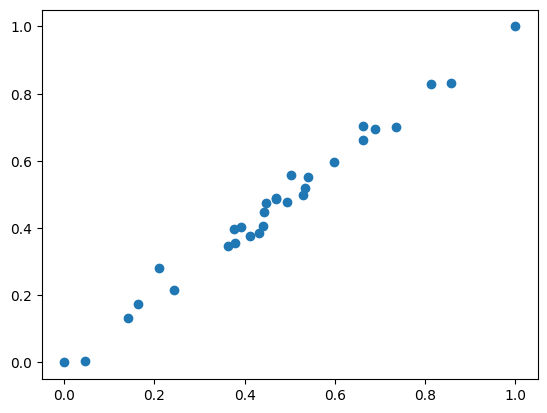

In [ ]:
plt.scatter(X, y)

In [ ]:
from sklearn.model_selection import train_test_split

X_train_main, X_test_main, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

### polynomial features to data


In [ ]:
# Create a high-degree polynomial model

from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(15)
X_train = poly.fit_transform(X_train_main)
X_test = poly.fit_transform(X_test_main)

### utility function

In [ ]:
# Generate lots of points in order to plot the polynomial
xx = np.linspace(0,1,500)
qx = np.array([[i] for i in xx])
X_plot_pred = poly.fit_transform(qx)

### Linear Regression without Regularization:


In [ ]:
def mse(y_true, y_predicted):
    return np.mean((y_true - y_predicted)**2)

In [ ]:
class LinearRegression:
  ## todo
  def __init__(self, lr=0.01, iter=500):
    self.lr = lr
    self.iter = iter
    self.weights = None
    self.bias = None
    self.cost = list()

  def fit(self, X, y):
    y=y.ravel()

    num_samples, num_features = X.shape
    self.weights = np.zeros(num_features)
    self.bias = 0

    for i in range(self.iter):
      y_pred = self.predict(X)
      cost_val = mse(y, y_pred)
      self.cost.append(cost_val)

      dw = (1 / num_samples) * np.dot(X.T , (y_pred - y))
      db = (1 / num_samples) * np.sum(y_pred - y)

      self.weights = self.weights - self.lr*dw
      self.bias = self.bias - self.lr*db

  def predict(self, X):

    return np.dot(X, self.weights) + self.bias


In [ ]:
lin_reg = LinearRegression(iter=10000, lr=0.05)

In [ ]:
lin_reg.fit(X_train, y_train)
qy = lin_reg.predict(X_plot_pred)

In [ ]:
# Filter so that the polynomial doesn't go off the graph.
qq = []
for i in qy:
    if i <= 1 and i >= 0:
        qq.append(i)
    else:
        qq.append(0)
qq = np.array(qq)

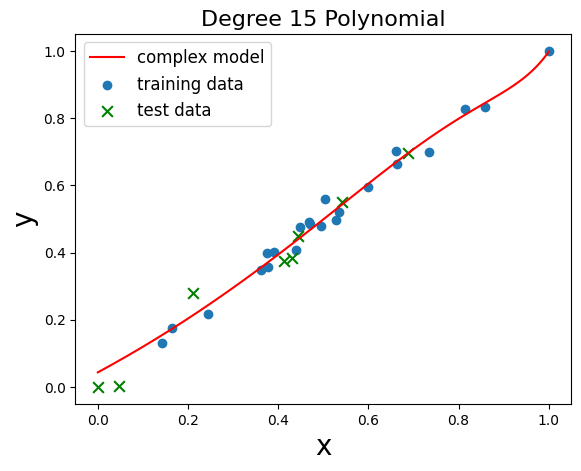

In [ ]:
## plot
fig = plt.figure()
ax1 = fig.add_subplot(111)

ax1.set_ylabel('y', fontsize=20)
ax1.set_xlabel('x', fontsize=20)
ax1.set_title('Degree 15 Polynomial', fontsize=16)

plt.plot(xx, qq, color='red', label="complex model")
plt.scatter(X_train_main, y_train, label="training data")
plt.scatter(X_test_main, y_test, color="green", marker="x", label="test data", s=60)

plt.legend(prop={'size': 12})

### Regularization:

In [ ]:
class RidgeRegression:
    def __init__(self, lr=0.01, iter=500, alpha=.1):
        self.lr = lr
        self.iter = iter
        self.alpha = alpha
        self.weights = None
        self.bias = None
        self.cost = []

    def fit(self, X, y):
        y = y.ravel()
        num_samples, num_features = X.shape
        self.weights = np.zeros(num_features)
        self.bias = 0

        for i in range(self.iter):
            y_pred = self.predict(X)
            error = y_pred - y
            cost_val = mse(y, y_pred)

            cost_val += self.alpha * np.sum(self.weights ** 2)

            self.cost.append(cost_val)

            # Gradients
            dw = (1 / num_samples) * np.dot(X.T, error)
            db = (1 / num_samples) * np.sum(error)

            dw += 2 * self.alpha * self.weights

            # Update weights
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict(self, X):
        return np.dot(X, self.weights) + self.bias

In [ ]:
ridge_regression = RidgeRegression(alpha=.01, iter=10000)
ridge_regression.fit(X_train, y_train)

In [ ]:
qq_2 = ridge_regression.predict(X_plot_pred)

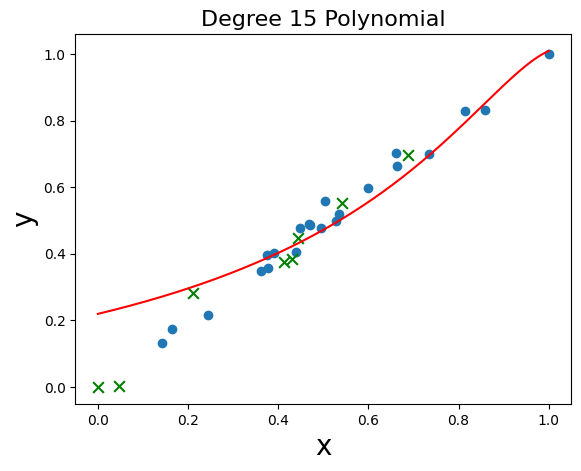

In [ ]:
fig = plt.figure()
ax1 = fig.add_subplot(111)

ax1.set_ylabel('y', fontsize=20)
ax1.set_xlabel('x', fontsize=20)
ax1.set_title('Degree 15 Polynomial', fontsize=16)

plt.plot(xx, qq_2, color='red', label="complex model")
plt.scatter(X_train_main, y_train, label="training data")
plt.scatter(X_test_main, y_test, color="green", marker="x", label="test data", s=60)

In [ ]:
linear_regression_errors = y_test - lin_reg.predict(X_test)
regularization_errors = y_test - qq_2
print(f"Linear Regression MSE: {np.mean(linear_regression_errors**2)}")
print(f"Ridge Regression MSE: {np.mean(regularization_errors**2)}")

Linear Regression MSE: 0.0974642597509324
Ridge Regression MSE: 0.14253758652719511
